# CatBoost Baseline

Train a baseline model using the original features. We will use its OOF ROC-AUC to evaluate future experiments.


## 1. Load Data

Load the training dataset and check its size and fraud rate.


In [14]:
import pandas as pd
import numpy as np
from pathlib import Path

root = Path("../playground-series-s6e11")

files = list(root.glob("**/*.csv"))

train_df = pd.read_csv(root / "train.csv")
print("Train shape:", train_df.shape)
print("Fraud rate:", f"{train_df['is_fraud'].mean():.2%}")
train_df.head()

Train shape: (699960, 26)
Fraud rate: 1.67%


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


## 2. Prepare Features

Separate features from the target, exclude `id`, and prepare categorical and boolean columns for CatBoost.


In [15]:
feature_cols = [c for c in train_df.columns if c not in ["id", "is_fraud"]]
X = train_df[feature_cols].copy()
y = train_df["is_fraud"].astype(int)

cat_features = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
bool_features = X.select_dtypes(include=["bool", "boolean"]).columns.tolist()

for col in cat_features:
    X[col] = X[col].astype("string").fillna("__MISSING__").astype(str)
for col in bool_features:
    X[col] = X[col].astype("Int64").astype(float)

print("Number of features:", len(feature_cols))
print("Categorical features:", cat_features)
print("Boolean features:", bool_features)
print("Class counts:", y.value_counts().to_dict())
assert y.nunique() == 2, "ROC-AUC needs both target classes"
assert np.isfinite(X.select_dtypes(include="number").dropna().to_numpy()).all(), "Infinite numerical values detected"

Number of features: 24
Categorical features: ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']
Boolean features: ['is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']
Class counts: {0: 688271, 1: 11689}


## 3. Train with 5-Fold Cross-Validation

Train five CatBoost models on stratified folds. Collect one out-of-fold (OOF) prediction per row and evaluate ROC-AUC.


In [16]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from catboost import CatBoostClassifier

N_SPLITS = 5
SEED = 42

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

model_params = {
    "iterations": 3000,
    "depth": 6,
    "learning_rate": 0.05,
    "loss_function": "Logloss",
    "eval_metric": "AUC",
    "random_seed": SEED,
    "verbose": False,
    "thread_count": -1,
}

oof_pred = np.zeros(len(X), dtype=float)
oof_fold = np.full(len(X), -1, dtype=int)
fold_scores = []
feature_importances = []
models = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X, y), start=1):
    X_train, X_valid = X.iloc[train_idx], X.iloc[valid_idx]
    y_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]

    model = CatBoostClassifier(**model_params)
    model.fit(
        X_train,
        y_train,
        cat_features=cat_features,
        eval_set=(X_valid, y_valid),
        early_stopping_rounds=100,
        use_best_model=True,
    )

    pred = model.predict_proba(X_valid)[:, 1]
    score = roc_auc_score(y_valid, pred)

    oof_pred[valid_idx] = pred
    oof_fold[valid_idx] = fold
    fold_scores.append(score)
    feature_importances.append(model.get_feature_importance())
    models.append(model)
    print(f"Fold {fold}: AUC={score:.6f}, best iteration={model.best_iteration_}")

assert (oof_fold > 0).all(), "Some rows did not receive OOF predictions"

oof_auc = roc_auc_score(y, oof_pred)
print(f"\nMean fold ROC-AUC: {np.mean(fold_scores):.6f} ± {np.std(fold_scores):.6f}")
print(f"Overall OOF ROC-AUC: {oof_auc:.6f}")

Fold 1: AUC=0.944562, best iteration=1485
Fold 2: AUC=0.947463, best iteration=1300
Fold 3: AUC=0.950552, best iteration=1011
Fold 4: AUC=0.946352, best iteration=1353
Fold 5: AUC=0.941891, best iteration=1449

Mean fold ROC-AUC: 0.946164 ± 0.002891
Overall OOF ROC-AUC: 0.946094


## 4. Evaluate the Baseline

Compare fold scores and visualize the overall OOF ROC curve.


,fold,roc_auc,best_iteration
0,1,0.944562,1485
1,2,0.947463,1300
2,3,0.950552,1011
3,4,0.946352,1353
4,5,0.941891,1449


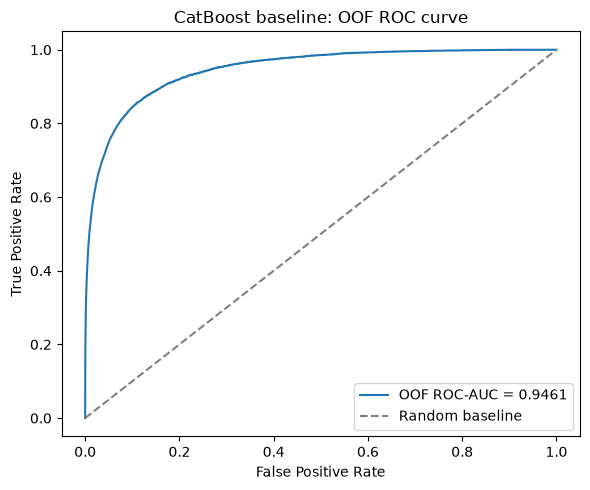

In [17]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt


fold_results = pd.DataFrame({
    "fold": range(1, N_SPLITS + 1),
    "roc_auc": fold_scores,
    "best_iteration": [m.best_iteration_ for m in models],
})
display(fold_results)

fpr, tpr, _ = roc_curve(y, oof_pred)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"OOF ROC-AUC = {oof_auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("CatBoost baseline: OOF ROC curve")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Feature Importance

Identify which original features CatBoost relies on most, averaged across folds.


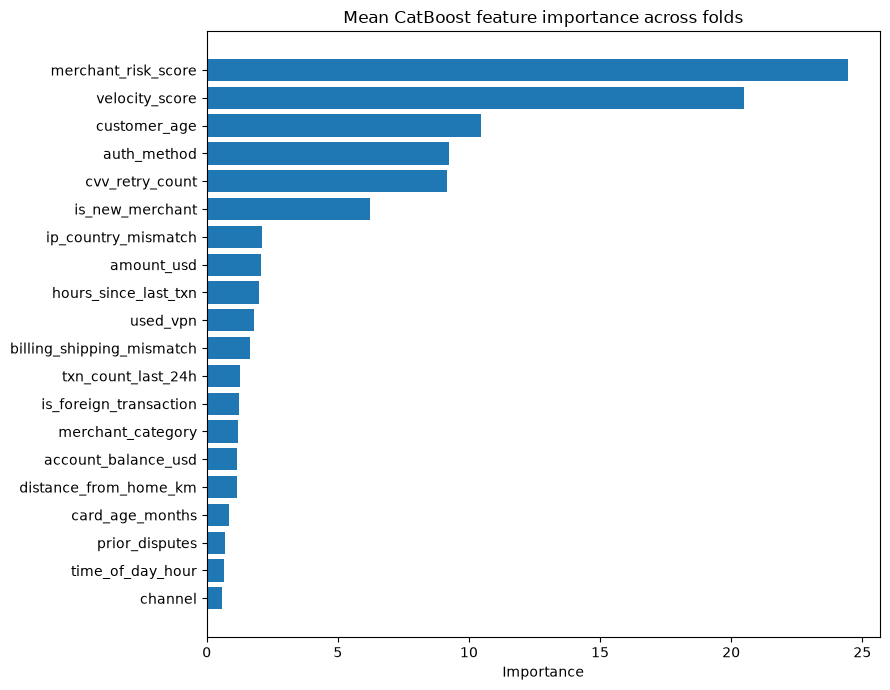

In [18]:
importance_df = pd.DataFrame({
    "feature": feature_cols,
    "importance": np.mean(feature_importances, axis=0),
}).sort_values("importance", ascending=False)

plt.figure(figsize=(9, 7))
top = importance_df.head(20).iloc[::-1]
plt.barh(top["feature"], top["importance"])
plt.title("Mean CatBoost feature importance across folds")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 6. Save Results

Save OOF predictions, fold scores, feature importance, and model settings for future comparisons.


In [19]:
import json

OUTPUT_DIR = Path("baseline_artifacts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

oof_df = pd.DataFrame({
    "id": train_df["id"] if "id" in train_df.columns else np.arange(len(train_df)),
    "is_fraud": y,
    "fold": oof_fold,
    "oof_pred": oof_pred,
})
oof_df.to_csv(OUTPUT_DIR / "baseline_oof.csv", index=False)
fold_results.to_csv(OUTPUT_DIR / "baseline_fold_scores.csv", index=False)
importance_df.to_csv(OUTPUT_DIR / "baseline_feature_importance.csv", index=False)

summary = {
    "experiment": "E00_original_features",
    "random_seed": SEED,
    "n_splits": N_SPLITS,
    "n_features": len(feature_cols),
    "feature_cols": feature_cols,
    "cat_features": cat_features,
    "model_params": model_params,
    "fold_auc": [float(s) for s in fold_scores],
    "mean_fold_auc": float(np.mean(fold_scores)),
    "std_fold_auc": float(np.std(fold_scores)),
    "overall_oof_auc": float(oof_auc),
}
(OUTPUT_DIR / "baseline_summary.json").write_text(
    json.dumps(summary, indent=2), encoding="utf-8"
)
print("Saved baseline artifacts to:", OUTPUT_DIR.resolve())

Saved baseline artifacts to: /Users/ulad/kaggle/fraud_detection/notebooks/baseline_artifacts
